# Where airlines lose time: carrier-attributable delay in US domestic flights

*This analysis uses US DOT (BTS) flight data rather than Singapore data, since CAAS/data.gov.sg only publishes aggregate monthly figures for Changi — no flight-level, cause-coded delay data is publicly available. BTS was chosen as the best available public dataset with the granularity needed for this kind of analysis.*

**Question.** Which airports or carriers show disproportionately high carrier-attributable delay, and does time-of-day or day-of-week make it worse?

**What "carrier-attributable" means.** BTS splits each delay of 15+ minutes into five causes. *Carrier* delay covers causes inside the airline's control: maintenance, crew, cleaning, fuelling, baggage. BTS has no separate "mechanical" field, so this is **not** a measure of mechanical problems. Weather, air-traffic-system (NAS) and security delays sit outside the airline's control. Late-arriving-aircraft delay is knock-on delay from an earlier flight and is kept separate.

In [1]:
import os, sys
from pathlib import Path

ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT / "src"))

import pandas as pd
from IPython.display import Markdown, display
from aviation_delays import data, metrics, charts
from aviation_delays.data import carrier_label

pd.set_option("display.float_format", "{:,.2f}".format)
charts.apply_style()
FIG_DIR = ROOT / "report" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

DATA_PATH = Path(os.environ.get("AVIATION_DATA", data.PROCESSED_PATH))
flights = data.load_processed(DATA_PATH)
af = data.analysis_frame(flights)

MIN_CARRIER_FLIGHTS = 50_000   # from 01_data_check
MIN_AIRPORT_FLIGHTS = 20_000
FLAG_INDEX = 1.2               # "disproportionate" = 20%+ above the network rate...
# ...overall, after controlling for mix, and in every year separately.

net = metrics.network_summary(af)
period = f"{af['date'].min():%b %Y} – {af['date'].max():%b %Y}"
n_years = af["date"].dt.year.nunique()
years_text = " and ".join(str(y) for y in sorted(af["date"].dt.year.unique()))
FULL_DAY = dict(zip(data.DAY_NAMES, ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]))

def flag(table):
    year_cols = [c for c in table.columns if c.startswith("index_")]
    ok = (table["index"] >= FLAG_INDEX) & (table["adj_index"] >= FLAG_INDEX)
    return table.index[ok & (table[year_cols] >= FLAG_INDEX).all(axis=1)].tolist()

by_carrier = (
    metrics.group_metrics(af, "carrier", min_flights=MIN_CARRIER_FLIGHTS)
    .join(metrics.mix_adjusted(af, "carrier", "origin")[["adj_index"]])
    .join(metrics.yearly_index(af, "carrier"))
)
by_airport = (
    metrics.group_metrics(af, "origin", min_flights=MIN_AIRPORT_FLIGHTS)
    .join(metrics.mix_adjusted(af, "origin", "carrier")[["adj_index"]])
    .join(metrics.yearly_index(af, "origin"))
)
flagged_carriers = flag(by_carrier)
flagged_airports = flag(by_airport)

by_hour = metrics.group_metrics(af, "dep_hour").sort_index()
by_dow = metrics.group_metrics(af, "day_of_week").sort_index().rename(index=dict(enumerate(data.DAY_NAMES)))
day_hours = by_hour.loc[5:23, "carrier_min_per_flight"]  # 00-04 has <1% of flights
hour_lo, hour_hi = day_hours.idxmin(), day_hours.idxmax()
hour_ratio = day_hours.max() / day_hours.min()

bands = {c: metrics.excess_by_band(af, c) for c in flagged_carriers}
FIRST_WAVE = "<09:00"

# Robustness: drop the CrowdStrike outage window (19-28 Jul 2024)
outage = af["date"].between("2024-07-19", "2024-07-28")
ex_outage = metrics.group_metrics(af[~outage], "carrier", min_flights=MIN_CARRIER_FLIGHTS).join(
    metrics.mix_adjusted(af[~outage], "carrier", "origin")[["adj_index"]]
)

def names(codes):
    labels = [data.CARRIER_NAMES.get(c, c).replace(" (regional)", "") + f" ({c})" for c in codes]
    return labels[0] if len(labels) == 1 else ", ".join(labels[:-1]) + " and " + labels[-1]

def hours(x):
    return f"{round(x, -2):,.0f}"

In [2]:
display(Markdown(f"**Data:** {period}, {int(net['flights']):,} completed flights. Carrier-attributable delay averages {net['carrier_min_per_flight']:.1f} min per flight and is {net['carrier_share']:.0%} of all cause-coded delay minutes."))

**Data:** Jan 2024 – Dec 2025, 13,844,730 completed flights. Carrier-attributable delay averages 5.2 min per flight and is 33% of all cause-coded delay minutes.

In [3]:
# The narrative below states these facts; stop rather than publish a sentence the data no longer supports.
assert flagged_carriers, "no carrier meets the flag rule: rewrite the summary"
assert all(bands[c]["excess_hours_per_year"].idxmax() == FIRST_WAVE for c in flagged_carriers), "first wave is no longer the worst band"
assert all(ex_outage.loc[c, "index"] >= FLAG_INDEX and ex_outage.loc[c, "adj_index"] >= FLAG_INDEX for c in flagged_carriers)

first_wave_total = sum(bands[c].loc[FIRST_WAVE, "excess_hours_per_year"] for c in flagged_carriers)
rates = " and ".join(f"{by_carrier.loc[c, 'carrier_min_per_flight']:.1f}" for c in flagged_carriers)
display(Markdown(f"""
## Summary

**{names(flagged_carriers)}** have disproportionately high carrier-attributable delay: {rates} minutes per flight,
against a network average of {net['carrier_min_per_flight']:.1f}. They stay at least {by_carrier.loc[flagged_carriers, 'adj_index'].min():.1f}× the rate
of other airlines flying from the same airports, in {years_text} separately.

**Time of day makes it worse.** Across the network, carrier-attributable delay per flight is {hour_ratio:.1f}× higher
at {hour_hi}:00 than at {hour_lo}:00, and {FULL_DAY[by_dow['carrier_min_per_flight'].idxmax()]} is the worst day of the week. But for both flagged carriers the
biggest excess is in the **first wave**: departures scheduled before 09:00.

**Recommendation:** {names(flagged_carriers)} should target first-wave departure readiness. Bringing their
pre-09:00 departures down to the network's pre-09:00 rate would remove about **{hours(first_wave_total)} carrier-attributable
delay hours a year**. That is before counting the knock-on delay those early flights pass to the rest of the day.
"""))


## Summary

**SkyWest (OO) and American (AA)** have disproportionately high carrier-attributable delay: 8.0 and 7.2 minutes per flight,
against a network average of 5.2. They stay at least 1.3× the rate
of other airlines flying from the same airports, in 2024 and 2025 separately.

**Time of day makes it worse.** Across the network, carrier-attributable delay per flight is 2.0× higher
at 22:00 than at 10:00, and Sunday is the worst day of the week. But for both flagged carriers the
biggest excess is in the **first wave**: departures scheduled before 09:00.

**Recommendation:** SkyWest (OO) and American (AA) should target first-wave departure readiness. Bringing their
pre-09:00 departures down to the network's pre-09:00 rate would remove about **20,600 carrier-attributable
delay hours a year**. That is before counting the knock-on delay those early flights pass to the rest of the day.


## 1 · Carriers

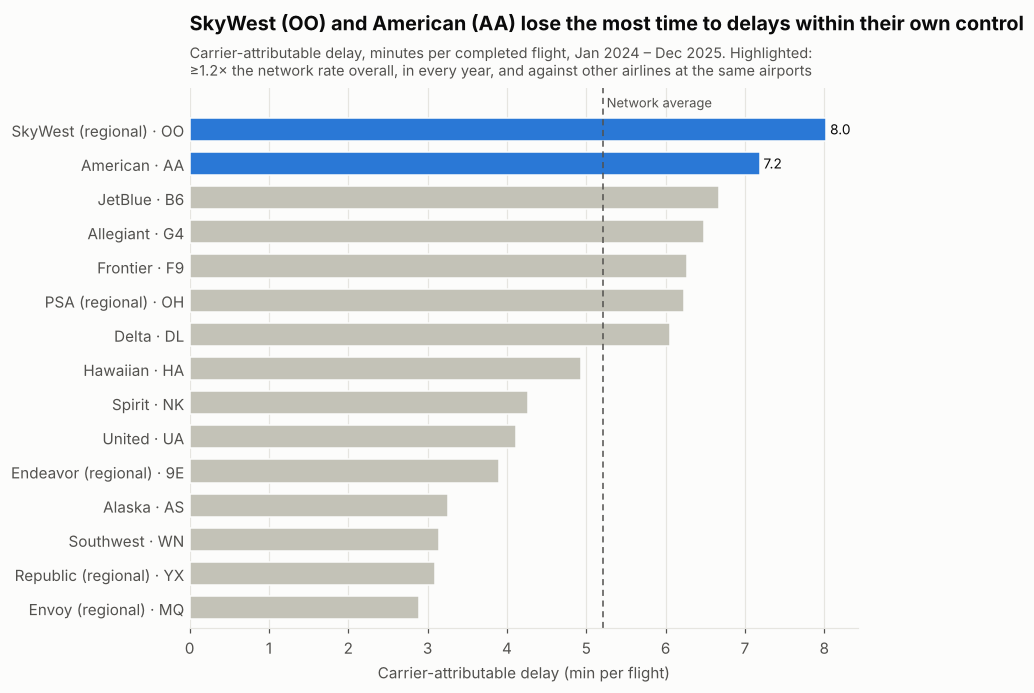

In [4]:
fig = charts.ranked_bars(
    by_carrier.rename(index=carrier_label), "carrier_min_per_flight",
    title=f"{names(flagged_carriers)} lose the most time to delays within their own control",
    subtitle=f"Carrier-attributable delay, minutes per completed flight, {period}. Highlighted: ≥{FLAG_INDEX:.1f}× the network "
             "rate overall, in every year, and against other airlines at the same airports",
    xlabel="Carrier-attributable delay (min per flight)",
    highlight=[carrier_label(c) for c in flagged_carriers], reference=net["carrier_min_per_flight"], top_n=None,
)
fig.savefig(FIG_DIR / "1_carriers.png", bbox_inches="tight")

In [5]:
lines = []
for c in flagged_carriers:
    r = by_carrier.loc[c]
    lines.append(
        f"- **{names([c])}**: {r['carrier_min_per_flight']:.1f} min per flight, {r['index']:.2f}× the network; "
        f"{r['adj_index']:.2f}× after controlling for airports flown; "
        + ", ".join(f"{col[-4:]}: {r[col]:.2f}×" for col in by_carrier.columns if col.startswith("index_"))
        + f". {hours(r['excess_hours'] / n_years)} excess delay hours a year."
    )
oo_like = af[af["carrier_delay"] > 0].groupby("carrier", observed=True)["carrier_delay"].median()
near_miss = by_carrier[(by_carrier["index"] >= FLAG_INDEX) & ~by_carrier.index.isin(flagged_carriers)]
display(Markdown(f"""
**Finding 1 · Carriers.** Two airlines meet every test:

{chr(10).join(lines)}

They fail in different ways. When a carrier-caused delay happens, the typical one lasts
{oo_like.get('OO', float('nan')):.0f} min at SkyWest and {oo_like.get('AA', float('nan')):.0f} min at American (network: {af.loc[af['carrier_delay'] > 0, 'carrier_delay'].median():.0f} min).
They also happen on {by_carrier.loc['OO', 'carrier_delayed_rate']:.0%} and {by_carrier.loc['AA', 'carrier_delayed_rate']:.0%} of flights
(network: {net['carrier_delayed_rate']:.0%}). So SkyWest's delays are longer, and American's are more frequent.

Above {FLAG_INDEX:.1f}× overall but not in every year or after the mix control: {names(near_miss.index.tolist()) if len(near_miss) else 'none'}.
For example, JetBlue's rate fell from {by_carrier.loc['B6', 'index_2024']:.2f}× in 2024 to {by_carrier.loc['B6', 'index_2025']:.2f}× in 2025.
"""))


**Finding 1 · Carriers.** Two airlines meet every test:

- **SkyWest (OO)**: 8.0 min per flight, 1.54× the network; 1.34× after controlling for airports flown; 2024: 1.51×, 2025: 1.56×. 36,500 excess delay hours a year.
- **American (AA)**: 7.2 min per flight, 1.38× the network; 1.33× after controlling for airports flown; 2024: 1.43×, 2025: 1.32×. 31,600 excess delay hours a year.

They fail in different ways. When a carrier-caused delay happens, the typical one lasts
35 min at SkyWest and 17 min at American (network: 19 min).
They also happen on 11% and 15% of flights
(network: 12%). So SkyWest's delays are longer, and American's are more frequent.

Above 1.2× overall but not in every year or after the mix control: JetBlue (B6), Allegiant (G4) and Frontier (F9).
For example, JetBlue's rate fell from 1.54× in 2024 to 1.02× in 2025.


## 2 · Airports
Grouped by **origin** airport, where the delay was incurred.

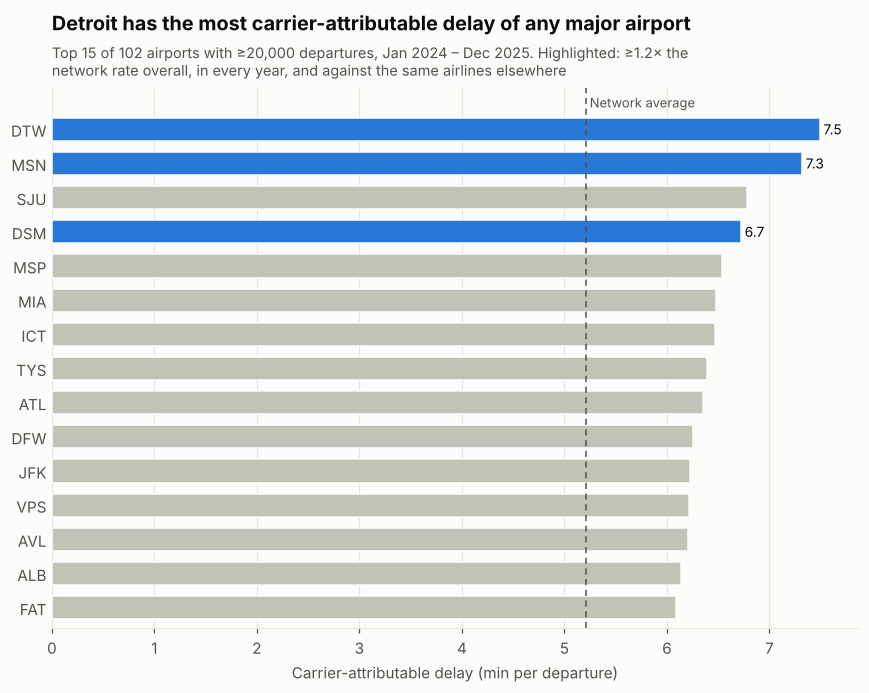

In [6]:
fig = charts.ranked_bars(
    by_airport, "carrier_min_per_flight",
    title="Detroit has the most carrier-attributable delay of any major airport" if flagged_airports[:1] == ["DTW"]
          else "Airports with the most carrier-attributable delay per departure",
    subtitle=f"Top {min(15, len(by_airport))} of {len(by_airport)} airports with ≥{MIN_AIRPORT_FLIGHTS:,} departures, {period}. "
             f"Highlighted: ≥{FLAG_INDEX:.1f}× the network rate overall, in every year, and against the same airlines elsewhere",
    xlabel="Carrier-attributable delay (min per departure)",
    highlight=flagged_airports, reference=net["carrier_min_per_flight"], top_n=15,
)
fig.savefig(FIG_DIR / "2_airports.png", bbox_inches="tight")

In [7]:
lines = []
for a in flagged_airports:
    r = by_airport.loc[a]
    top = af.loc[af["origin"] == a, "carrier"].value_counts(normalize=True).head(2)
    mix = ", ".join(f"{names([c])} {s:.0%}" for c, s in top.items())
    lines.append(f"- **{a}**: {r['carrier_min_per_flight']:.1f} min per departure ({r['index']:.2f}×; {r['adj_index']:.2f}× against "
                 f"the same airlines elsewhere). {int(r['flights']):,} departures; main operators {mix}.")
display(Markdown(f"""
**Finding 2 · Airports.** {len(flagged_airports)} of {len(by_airport)} major airports meet every test:

{chr(10).join(lines) if lines else '- none'}

Airports matter less than carriers. The airport effect is smaller once airline mix is controlled for, and the flagged airports
add up to {hours(by_airport.loc[flagged_airports, 'excess_hours'].sum() / n_years)} excess hours a year, against
{hours(by_carrier.loc[flagged_carriers, 'excess_hours'].sum() / n_years)} for the flagged carriers.
"""))


**Finding 2 · Airports.** 3 of 102 major airports meet every test:

- **DTW**: 7.5 min per departure (1.44×; 1.25× against the same airlines elsewhere). 250,604 departures; main operators Delta (DL) 47%, SkyWest (OO) 21%.
- **MSN**: 7.3 min per departure (1.40×; 1.26× against the same airlines elsewhere). 24,110 departures; main operators SkyWest (OO) 21%, American (AA) 17%.
- **DSM**: 6.7 min per departure (1.29×; 1.27× against the same airlines elsewhere). 29,443 departures; main operators American (AA) 15%, United (UA) 14%.

Airports matter less than carriers. The airport effect is smaller once airline mix is controlled for, and the flagged airports
add up to 5,600 excess hours a year, against
68,100 for the flagged carriers.


## 3 · Time of day and day of week
By **scheduled** departure hour (local time), so a late flight doesn't move into a later hour.

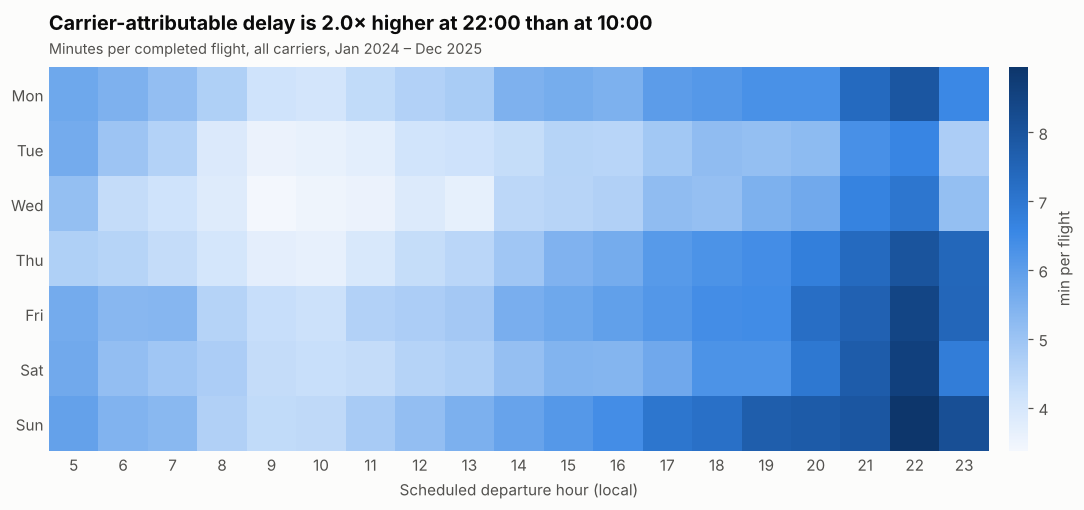

In [8]:
hour_dow = metrics.grid(af[af["dep_hour"].between(5, 23)], "day_of_week", "dep_hour", min_flights=1_000)
hour_dow.index = [data.DAY_NAMES[i] for i in hour_dow.index]
fig = charts.heatmap(
    hour_dow,
    title=f"Carrier-attributable delay is {hour_ratio:.1f}× higher at {hour_hi}:00 than at {hour_lo}:00",
    subtitle=f"Minutes per completed flight, all carriers, {period}",
    xlabel="Scheduled departure hour (local)", colorbar_label="min per flight",
)
fig.savefig(FIG_DIR / "3_hour_weekday.png", bbox_inches="tight")

In [9]:
band_table = pd.DataFrame({
    names([c]): bands[c]["vs_network"].map("{:.2f}×".format) + " · " + bands[c]["excess_hours_per_year"].map(lambda x: hours(x)) + " h/yr"
    for c in flagged_carriers
})
band_table.index.name = "Scheduled departure"
fw = {c: bands[c].loc[FIRST_WAVE] for c in flagged_carriers}
display(Markdown(f"""
**Finding 3 · Time of day and day of week.** Across the network, carrier-attributable delay is lowest in the late morning
({day_hours.min():.1f} min per flight at {hour_lo}:00) and climbs through the afternoon and evening to {day_hours.max():.1f} min at {hour_hi}:00.
{FULL_DAY[by_dow['carrier_min_per_flight'].idxmax()]} ({by_dow['carrier_min_per_flight'].max():.1f} min) is the worst day and
{FULL_DAY[by_dow['carrier_min_per_flight'].idxmin()]} ({by_dow['carrier_min_per_flight'].min():.1f}) the best. The weekday effect is smaller than the hour-of-day effect.

For the flagged carriers, the gap over the network is widest early in the day, when the network itself is at its best.
Before 09:00 they run {' and '.join(f"{fw[c]['vs_network']:.2f}×" for c in flagged_carriers)} the network rate.
That band is {' and '.join(f"{fw[c]['share_of_flights']:.0%}" for c in flagged_carriers)} of their flights
but {' and '.join(f"{fw[c]['share_of_excess']:.0%}" for c in flagged_carriers)} of their excess delay hours. Most of these flights start the day
from an overnight position. That points at readiness (maintenance sign-off, crew, aircraft preparation), though the BTS data can't say which.

Each carrier's rate against the network in each time band, and the excess delay hours a year:

{band_table.to_markdown()}
"""))


**Finding 3 · Time of day and day of week.** Across the network, carrier-attributable delay is lowest in the late morning
(3.9 min per flight at 10:00) and climbs through the afternoon and evening to 8.0 min at 22:00.
Sunday (6.0 min) is the worst day and
Wednesday (4.5) the best. The weekday effect is smaller than the hour-of-day effect.

For the flagged carriers, the gap over the network is widest early in the day, when the network itself is at its best.
Before 09:00 they run 1.76× and 1.51× the network rate.
That band is 21% and 26% of their flights
but 28% and 33% of their excess delay hours. Most of these flights start the day
from an overnight position. That points at readiness (maintenance sign-off, crew, aircraft preparation), though the BTS data can't say which.

Each carrier's rate against the network in each time band, and the excess delay hours a year:

| Scheduled departure   | SkyWest (OO)        | American (AA)       |
|:----------------------|:--------------------|:--------------------|
| <09:00                | 1.76× · 10,300 h/yr | 1.51× · 10,300 h/yr |
| 09–13                 | 1.62× · 8,700 h/yr  | 1.33× · 4,900 h/yr  |
| 13–17                 | 1.48× · 8,100 h/yr  | 1.29× · 5,100 h/yr  |
| 17–21                 | 1.46× · 8,400 h/yr  | 1.33× · 7,100 h/yr  |
| 21+                   | 1.36× · 1,700 h/yr  | 1.40× · 3,600 h/yr  |


In [10]:
display(Markdown(f"""
## Recommendation

**Fix the first wave at {names(flagged_carriers)}.** Their pre-09:00 departures run
{' and '.join(f"{fw[c]['vs_network']:.1f}×" for c in flagged_carriers)} the network's carrier-attributable delay rate. Bringing them to the
network rate would remove about **{hours(first_wave_total)} delay hours a year**
({', '.join(f"{names([c])} {hours(fw[c]['excess_hours_per_year'])}" for c in flagged_carriers)}).
Likely places to look, which BTS can't separate: overnight maintenance sign-off, crew show-up and aircraft readiness
(cleaning, catering, fuelling) at the stations that launch the first wave. All of these are inside the airline's control, which is what this metric measures.

The number is conservative. A late first departure pushes delay onto later flights, and BTS books that as
*late-arriving aircraft* delay ({metrics.cause_breakdown(af).set_index('cause').loc['Late-arriving aircraft', 'share']:.0%} of all delay minutes), which is not counted here.
"""))


## Recommendation

**Fix the first wave at SkyWest (OO) and American (AA).** Their pre-09:00 departures run
1.8× and 1.5× the network's carrier-attributable delay rate. Bringing them to the
network rate would remove about **20,600 delay hours a year**
(SkyWest (OO) 10,300, American (AA) 10,300).
Likely places to look, which BTS can't separate: overnight maintenance sign-off, crew show-up and aircraft readiness
(cleaning, catering, fuelling) at the stations that launch the first wave. All of these are inside the airline's control, which is what this metric measures.

The number is conservative. A late first departure pushes delay onto later flights, and BTS books that as
*late-arriving aircraft* delay (40% of all delay minutes), which is not counted here.


## Caveats

- **Carrier delay ≠ mechanical delay.** BTS records maintenance in the same field as crew, cleaning, fuelling and baggage.
- **Short delays aren't counted.** Delay causes are only recorded for flights 15+ minutes late.
- **Knock-on delay is left out.** Late-arriving-aircraft delay is partly the carrier's own knock-on delay, but BTS doesn't record what caused it. Leaving it out of "carrier-attributable" makes the estimate conservative.
- **SkyWest is a regional carrier.** It flies under the United, Delta, American and Alaska brands but operates and reports these flights itself. Its delays are its own operation's, not the brand's.
- **The CrowdStrike outage doesn't change the findings.** The IT outage of 19 July 2024 hit Delta hardest. With 19–28 July 2024 removed, the same carriers are flagged (see appendix).
- **Delay causes are self-reported** by airlines. BTS covers US domestic flights by carriers above a revenue threshold, so the results may not carry over to other markets such as Changi.

## Future work (out of scope for this pass)

- Weather delay by airport and season
- Route and distance effects
- Station-level first-wave analysis for the flagged carriers (which origin airports drive the pre-09:00 excess)
- Predicting carrier-attributable delay; an interactive dashboard (Streamlit)

---

## Appendix: supporting tables

**Cause breakdown, network-wide**

In [11]:
metrics.cause_breakdown(af).assign(hours_per_year=lambda d: d["minutes"] / 60 / n_years).drop(columns="minutes")

,cause,share,hours_per_year
0,Late-arriving aircraft,0.40,"715,305.44"
1,Carrier,0.33,"601,247.00"
2,NAS (air traffic system),0.20,"367,547.69"
3,Weather,0.06,"110,871.55"
4,Security,0.00,"2,772.75"


**Carriers** (`index` = against the network; `adj_index` = against other airlines at the same airports; `index_YYYY` = that year only; `excess_hours` = whole period)

In [12]:
by_carrier.rename(index=carrier_label)

,flights,carrier_min_per_flight,carrier_delayed_rate,carrier_share,on_time_rate,index,excess_hours,adj_index,index_2024,index_2025
carrier,,,,,,,,,,
SkyWest (regional) · OO,1559088,8.02,0.11,0.49,0.80,1.54,"73,087.09",1.34,1.51,1.56
American · AA,1918957,7.18,0.15,0.33,0.74,1.38,"63,106.29",1.33,1.43,1.32
JetBlue · B6,462386,6.68,0.17,0.33,0.74,1.28,"11,304.55",1.26,1.54,1.02
Allegiant · G4,244774,6.49,0.11,0.32,0.77,1.24,"5,205.68",1.08,1.31,1.19
Frontier · F9,397672,6.27,0.13,0.27,0.72,1.20,"6,996.40",1.22,1.17,1.24
PSA (regional) · OH,460355,6.23,0.12,0.29,0.75,1.19,"7,788.59",1.11,1.01,1.36
Delta · DL,2010253,6.05,0.10,0.45,0.81,1.16,"28,223.56",1.08,1.15,1.18
Hawaiian · HA,156968,4.93,0.14,0.60,0.84,0.95,-741.77,1.47,0.81,1.07
Spirit · NK,446824,4.27,0.11,0.26,0.77,0.82,"-7,037.35",0.83,0.87,0.76


**Carriers with the CrowdStrike outage window (19–28 Jul 2024) removed**

In [13]:
ex_outage[["flights", "carrier_min_per_flight", "index", "adj_index"]].rename(index=carrier_label)

,flights,carrier_min_per_flight,index,adj_index
carrier,,,,
SkyWest (regional) · OO,1538381,7.98,1.57,1.35
American · AA,1891248,7.07,1.39,1.34
JetBlue · B6,455913,6.64,1.30,1.28
Allegiant · G4,240650,6.43,1.26,1.09
Frontier · F9,391598,6.26,1.23,1.24
PSA (regional) · OH,454190,6.12,1.20,1.12
Delta · DL,1985709,5.68,1.11,1.05
Hawaiian · HA,154775,4.93,0.97,1.48
Spirit · NK,439342,4.12,0.81,0.82


**Airports, top 20**

In [14]:
by_airport.head(20)

,flights,carrier_min_per_flight,carrier_delayed_rate,carrier_share,on_time_rate,index,excess_hours,adj_index,index_2024,index_2025
origin,,,,,,,,,,
DTW,250604,7.49,0.13,0.50,0.80,1.44,"9,514.79",1.25,1.38,1.50
MSN,24110,7.32,0.09,0.40,0.80,1.40,845.63,1.26,1.43,1.38
SJU,70036,6.78,0.14,0.37,0.77,1.30,"1,833.44",1.19,1.54,1.07
DSM,29443,6.72,0.09,0.38,0.80,1.29,740.81,1.27,1.38,1.20
MSP,237065,6.54,0.11,0.48,0.80,1.25,"5,236.65",1.07,1.20,1.31
MIA,217835,6.48,0.15,0.32,0.73,1.24,"4,616.07",1.10,1.33,1.16
ICT,20995,6.46,0.10,0.37,0.80,1.24,438.66,1.16,1.05,1.41
TYS,28936,6.40,0.10,0.35,0.79,1.23,571.18,1.09,1.05,1.44
ATL,646726,6.35,0.14,0.44,0.78,1.22,"12,301.41",1.12,1.15,1.30


**By scheduled departure hour and by weekday**

In [15]:
display(by_hour[["flights", "carrier_min_per_flight", "carrier_delayed_rate", "index"]])
by_dow[["flights", "carrier_min_per_flight", "carrier_delayed_rate", "index"]]

,flights,carrier_min_per_flight,carrier_delayed_rate,index
dep_hour,,,,
0,23179,6.75,0.10,1.30
1,7394,6.78,0.10,1.30
2,2810,4.85,0.09,0.93
3,1801,6.55,0.10,1.26
4,824,7.47,0.10,1.43
5,392090,5.49,0.06,1.05
6,962364,5.04,0.06,0.97
7,988059,4.84,0.07,0.93
8,954934,4.34,0.08,0.83


,flights,carrier_min_per_flight,carrier_delayed_rate,index
day_of_week,,,,
Mon,2088250,5.39,0.12,1.03
Tue,1893059,4.55,0.09,0.87
Wed,1910400,4.46,0.10,0.86
Thu,2046133,5.09,0.12,0.98
Fri,2061923,5.57,0.12,1.07
Sat,1788896,5.32,0.12,1.02
Sun,2056069,6.00,0.13,1.15


**Flagged carriers by time band**

In [16]:
pd.concat(bands, names=["carrier"])

flights  min_per_flight  network_min_per_flight  vs_network  \
carrier band                                                                  
OO      <09:00   332825            8.55                    4.85        1.76   
        09–13    403161            6.73                    4.15        1.62   
        13–17    396623            7.57                    5.13        1.48   
        17–21    350358            9.06                    6.19        1.46   
        21+       76121           10.16                    7.49        1.36   
AA      <09:00   505932            7.31                    4.85        1.51   
        09–13    428369            5.51                    4.15        1.33   
        13–17    420656            6.59                    5.13        1.29   
        17–21    418669            8.21                    6.19        1.33   
        21+      145331           10.46                    7.49        1.40   

                excess_hours_per_year  share_of_flights  share_of_excess  
carrier band                                                              
OO      <09:00              10,266.42              0.21             0.28  
        09–13                8,679.01              0.26             0.23  
        13–17                8,078.80              0.25             0.22  
        17–21                8,388.97              0.22             0.23  
        21+                  1,692.74              0.05             0.05  
AA      <09:00              10,349.32              0.26             0.33  
        09–13                4,856.02              0.22             0.16  
        13–17                5,133.16              0.22             0.17  
        17–21                7,065.07              0.22             0.23  
        21+                  3,603.44              0.08             0.12